In [1]:
# Gerekli kütüphaneleri projeye dahil ediyoruz

import os
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

# TensorFlow sürümünü kontrol ediyoruz
print("TensorFlow sürümü:", tf.__version__)

# Çalışma ortamını kontrol ediyoruz
print("GPU bilgisi:", tf.config.list_physical_devices('GPU'))

print("Kütüphaneler başarıyla yüklendi!")

TensorFlow sürümü: 2.21.0
GPU bilgisi: []
Kütüphaneler başarıyla yüklendi!


In [2]:
from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive.zip


In [3]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/garbage_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Veri seti başarıyla çıkarıldı!")

Veri seti başarıyla çıkarıldı!


In [4]:
print(os.listdir(extract_path))

['garbage_classification']


In [5]:
data_dir = os.path.join(extract_path, "garbage_classification")

print(os.listdir(data_dir))

['biological', 'paper', 'plastic', 'metal', 'cardboard', 'shoes', 'green-glass', 'battery', 'clothes', 'white-glass', 'trash', 'brown-glass']


In [6]:
for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)

    if os.path.isdir(folder_path):
        images = os.listdir(folder_path)
        print(folder, ":", len(images), "fotoğraf")

biological : 985 fotoğraf
paper : 1050 fotoğraf
plastic : 865 fotoğraf
metal : 769 fotoğraf
cardboard : 891 fotoğraf
shoes : 1977 fotoğraf
green-glass : 629 fotoğraf
battery : 945 fotoğraf
clothes : 5325 fotoğraf
white-glass : 775 fotoğraf
trash : 697 fotoğraf
brown-glass : 607 fotoğraf


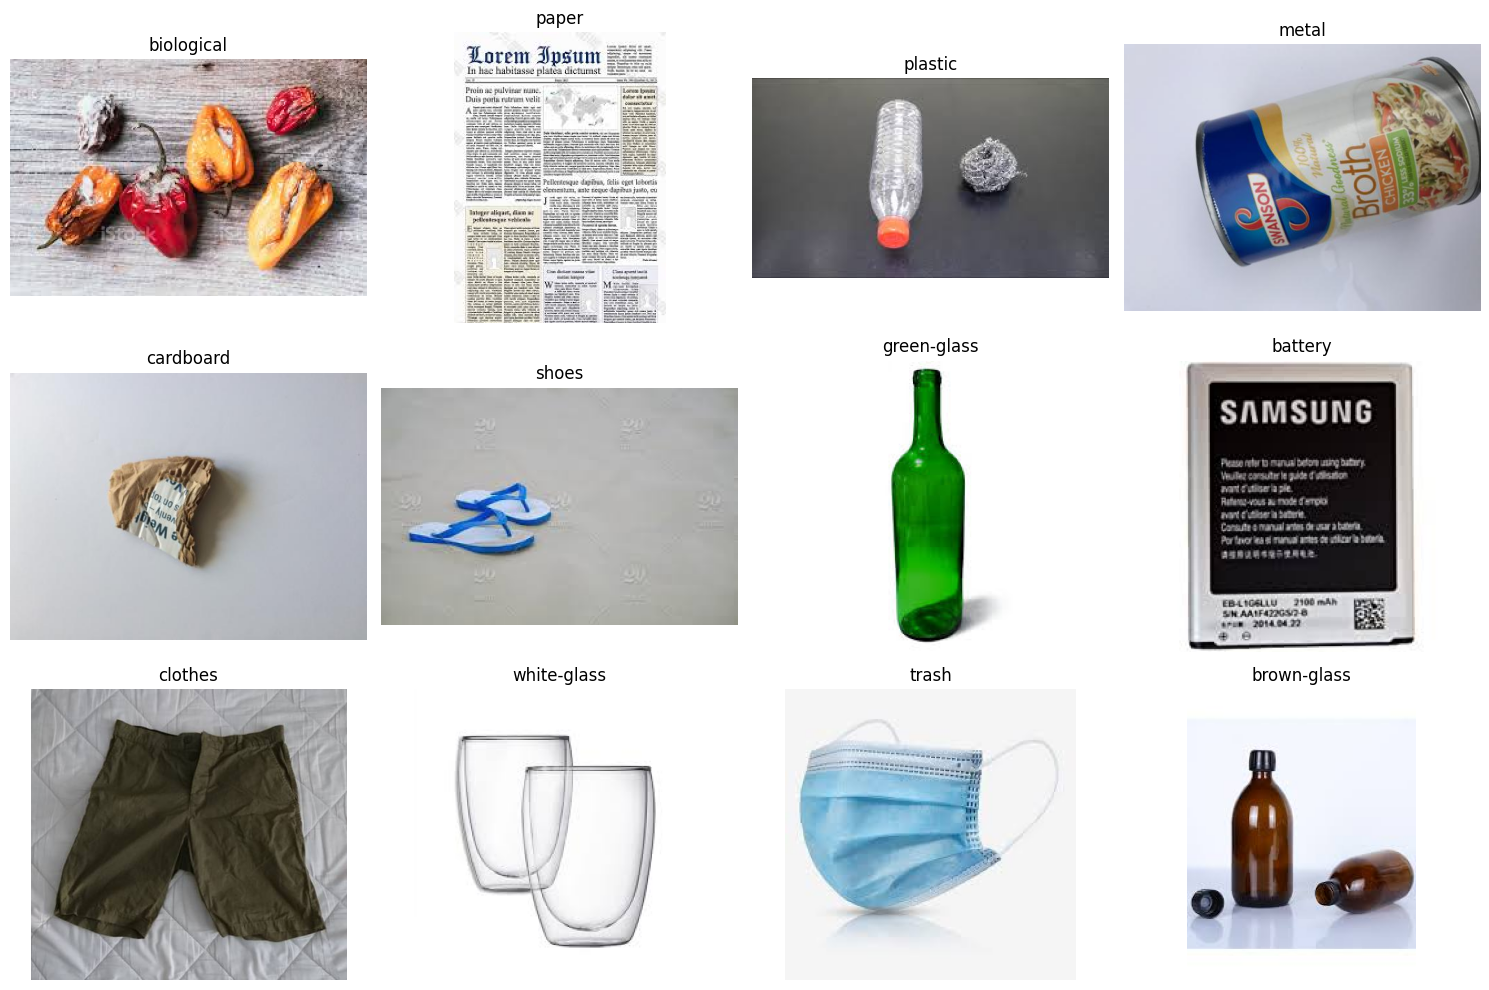

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 10))

for i, folder in enumerate(os.listdir(data_dir)):
    folder_path = os.path.join(data_dir, folder)

    if os.path.isdir(folder_path):
        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        if images:
            image_path = os.path.join(folder_path, images[0])
            image = Image.open(image_path).convert("RGB")

            plt.subplot(3, 4, i + 1)
            plt.imshow(image)
            plt.title(folder)
            plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:
# Görüntülerin boyutunu belirliyoruz
IMG_SIZE = (128, 128)

# Her seferinde işlenecek görüntü sayısı
BATCH_SIZE = 32

# Eğitim veri seti
train_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Doğrulama ve test veri seti
val_test_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Doğrulama ve test verilerini ikiye ayırıyoruz
val_batches = tf.data.experimental.cardinality(val_test_data)

validation_data = val_test_data.take(val_batches // 2)
test_data = val_test_data.skip(val_batches // 2)

print("Veri setleri hazır!")
print("Sınıflar:", train_data.class_names)


Found 15515 files belonging to 12 classes.
Using 10861 files for training.
Found 15515 files belonging to 12 classes.
Using 4654 files for validation.
Veri setleri hazır!
Sınıflar: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [9]:
from sklearn.model_selection import train_test_split

# Sınıf isimlerini belirle
class_names = sorted(os.listdir(data_dir))
class_names = [
    name for name in class_names
    if os.path.isdir(os.path.join(data_dir, name))
]

# Görüntü yollarını ve etiketlerini oluştur
image_paths = []
image_labels = []

for label, class_name in enumerate(class_names):
    folder = os.path.join(data_dir, class_name)

    for file in os.listdir(folder):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder, file))
            image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

# Önce %70 eğitim, %30 diğer veriler
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# Kalan %30'u iki eşit parçaya böl
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Eğitim:", len(X_train))
print("Doğrulama:", len(X_val))
print("Test:", len(X_test))
print("Sınıf sayısı:", len(class_names))


Eğitim: 10860
Doğrulama: 2327
Test: 2328
Sınıf sayısı: 12


In [10]:
# Görüntüleri okuma ve hazırlama fonksiyonu

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [128, 128])

    # Normalizasyon: 0-255 değerlerini 0-1 aralığına dönüştür
    image = image / 255.0

    return image, label


# Dosya yollarından TensorFlow veri setleri oluşturma
train_data = tf.data.Dataset.from_tensor_slices((X_train, y_train))
validation_data = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_data = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Görüntüleri işleme
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.map(
    load_image, num_parallel_calls=AUTOTUNE
)

validation_data = validation_data.map(
    load_image, num_parallel_calls=AUTOTUNE
)

test_data = test_data.map(
    load_image, num_parallel_calls=AUTOTUNE
)

# Gruplama ve performans ayarları
train_data = train_data.shuffle(1000).batch(32).prefetch(AUTOTUNE)
validation_data = validation_data.batch(32).prefetch(AUTOTUNE)
test_data = test_data.batch(32).prefetch(AUTOTUNE)

print("Görüntüler modele hazır!")

Görüntüler modele hazır!


In [11]:
for images, labels in train_data.take(1):
    print("Görüntü boyutu:", images.shape)
    print("Etiket boyutu:", labels.shape)
    print("Minimum piksel değeri:", tf.reduce_min(images).numpy())
    print("Maksimum piksel değeri:", tf.reduce_max(images).numpy())

Görüntü boyutu: (32, 128, 128, 3)
Etiket boyutu: (32,)
Minimum piksel değeri: 0.0
Maksimum piksel değeri: 1.0


In [12]:
from tensorflow.keras import layers, models

# CNN modelimizi oluşturuyoruz
model = models.Sequential([

    # Giriş görüntüsü
    layers.Input(shape=(128, 128, 3)),

    # Görüntü artırma
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),

    # 1. Evrişim katmanı
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # 2. Evrişim katmanı
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # 3. Evrişim katmanı
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Sınıflandırma katmanları
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # 12 sınıflı çıktı katmanı
    layers.Dense(12, activation="softmax")
])

# Modelin öğrenme ayarları
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Modelin yapısını göster
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,188 (12.61 MB)

 Trainable params: 3,306,188 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Sınıf ağırlıkları:")
print(class_weights)

Sınıf ağırlıkları:
{np.int64(0): np.float64(1.3691376701966718), np.int64(1): np.float64(1.3134978229317853), np.int64(2): np.float64(2.1294117647058823), np.int64(3): np.float64(1.4503205128205128), np.int64(4): np.float64(0.24282264555943117), np.int64(5): np.float64(2.0568181818181817), np.int64(6): np.float64(1.6821561338289963), np.int64(7): np.float64(1.2312925170068028), np.int64(8): np.float64(1.4933993399339933), np.int64(9): np.float64(0.6539017341040463), np.int64(10): np.float64(1.8545081967213115), np.int64(11): np.float64(1.6666666666666667)}


In [14]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Eğitim sırasında kullanılacak kontroller
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "en_iyi_model.keras",
    monitor="val_loss",
    save_best_only=True
)

# Modelin eğitilmesi
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 386s 1s/step - accuracy: 0.3545 - loss: 1.8993 - val_accuracy: 0.5333 - val_loss: 1.3482
Epoch 2/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 362s 1s/step - accuracy: 0.5242 - loss: 1.4693 - val_accuracy: 0.5810 - val_loss: 1.2192
Epoch 3/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 381s 1s/step - accuracy: 0.5657 - loss: 1.3460 - val_accuracy: 0.6347 - val_loss: 1.1363
Epoch 4/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 382s 1s/step - accuracy: 0.6015 - loss: 1.2395 - val_accuracy: 0.6476 - val_loss: 1.0831
Epoch 5/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - accuracy: 0.6242 - loss: 1.1709 - val_accuracy: 0.6614 - val_loss: 1.0227
Epoch 6/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 360s 1s/step - accuracy: 0.6378 - loss: 1.1308 - val_accuracy: 0.6476 - val_loss: 1.0861
Epoch 7/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.6558 - loss: 1.0737 - val_accuracy: 0.7125 - val_loss: 0.8780
Epoch 8/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 354s 1s/step - accuracy: 0.6727 - loss: 1.0190 - val_accu

In [15]:
print("Eğitim geçmişi:", len(history.epoch))
print("Son tamamlanan epoch:", history.epoch[-1] + 1)

Eğitim geçmişi: 11
Son tamamlanan epoch: 11


In [16]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test doğruluğu:", test_accuracy)
print("Test kaybı:", test_loss)

73/73 ━━━━━━━━━━━━━━━━━━━━ 21s 291ms/step - accuracy: 0.7161 - loss: 0.8909
Test doğruluğu: 0.7160652875900269
Test kaybı: 0.8909311294555664


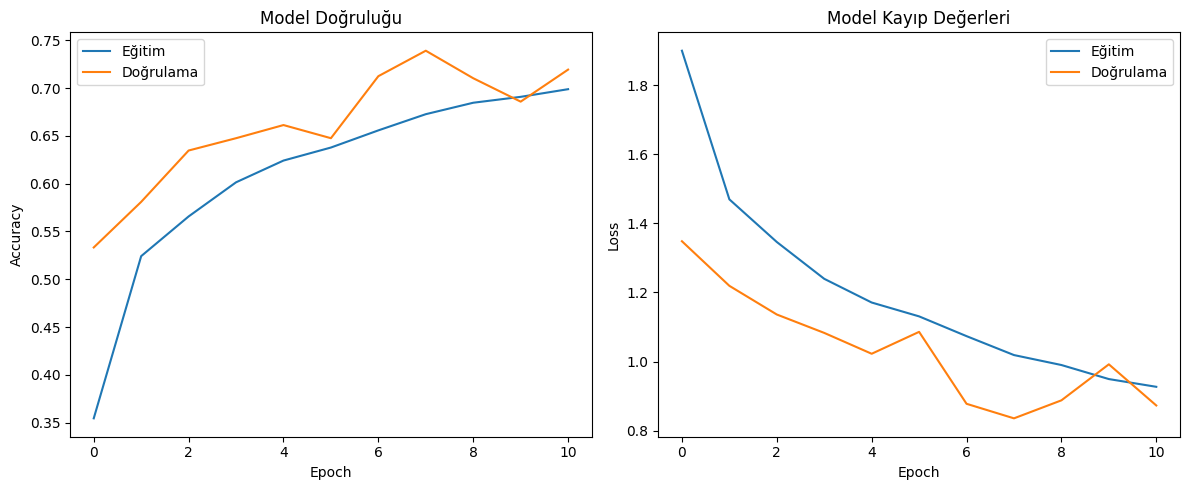

In [17]:
plt.figure(figsize=(12, 5))

# Doğruluk grafiği
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Eğitim")
plt.plot(history.history["val_accuracy"], label="Doğrulama")
plt.title("Model Doğruluğu")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Kayıp grafiği
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Eğitim")
plt.plot(history.history["val_loss"], label="Doğrulama")
plt.title("Model Kayıp Değerleri")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [18]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([labels.numpy() for images, labels in test_data])

y_pred_prob = model.predict(test_data)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 297ms/step
              precision    recall  f1-score   support

     battery       0.71      0.65      0.68       142
  biological       0.59      0.84      0.69       148
 brown-glass       0.73      0.81      0.77        91
   cardboard       0.62      0.79      0.70       134
     clothes       0.91      0.82      0.86       799
 green-glass       0.83      0.90      0.87        94
       metal       0.49      0.34      0.40       115
       paper       0.59      0.73      0.65       158
     plastic       0.58      0.45      0.50       130
       shoes       0.66      0.60      0.63       297
       trash       0.59      0.73      0.66       104
 white-glass       0.54      0.56      0.55       116

    accuracy                           0.72      2328
   macro avg       0.65      0.69      0.66      2328
weighted avg       0.72      0.72      0.72      2328



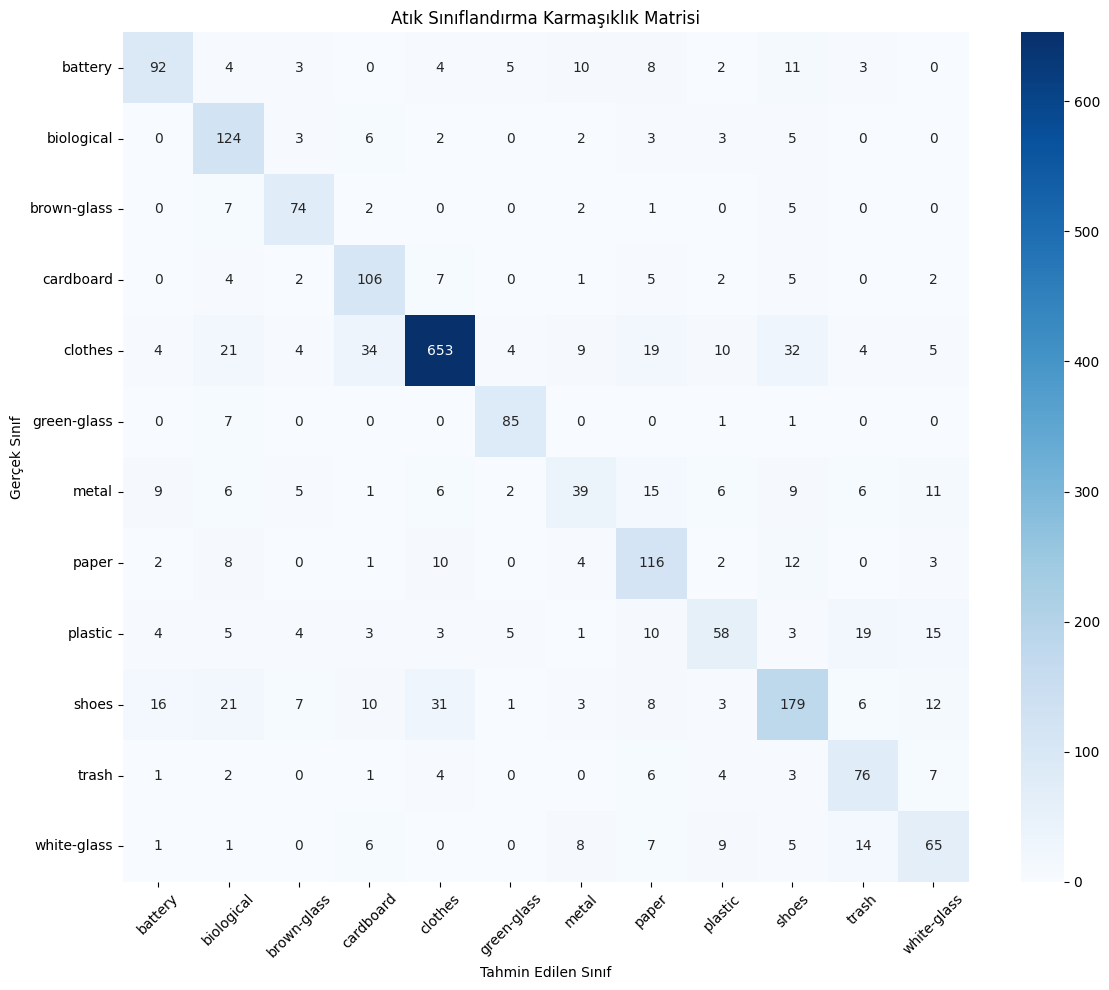

In [19]:

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.title("Atık Sınıflandırma Karmaşıklık Matrisi")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [21]:
model.save("atik_siniflandirma_model.keras")

print("Model başarıyla kaydedildi!")

Model başarıyla kaydedildi!


In [22]:
from google.colab import files

files.download("atik_siniflandirma_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>